# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:


Dataset Title: 2024 Fuel Economy Guide Datafile

Publisher: U.S. Department of Energy (DOE) and U.S. Environmental Protection Agency (EPA)

Source URL: https://www.fueleconomy.gov/feg/download.shtml

Data Dictionary/Documentation: https://www.fueleconomy.gov/feg/ws/index.shtml

Access Date: October 9, 2026

**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:


The dataset contains fuel economy information for vehicles from the 2024 model year in the United States. Each row represents a vehicle configuration, which may include differences in manufacturer, model, engine, transmission, or fuel type. The dataset provides information about vehicle characteristics and fuel efficiency, allowing comparisons between different vehicle categories.

The information is published by the U.S. Department of Energy and the Environmental Protection Agency. Fuel economy estimates are developed using standardized vehicle testing procedures conducted by manufacturers and the EPA. The dataset focuses on vehicles available in the U.S. market rather than vehicles worldwide.

**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer:


I reviewed the datasets used in previous class demonstrations and my earlier lab assignments. Previous datasets included Billboard songs, Titanic passengers, Pokémon, penguins, and video game sales. The 2024 Fuel Economy Guide dataset has not appeared in the course materials or my previous submissions that I reviewed. I selected it because it provides a new topic with categorical vehicle classifications and multiple quantitative measurements suitable for comparing distributions.

## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
fuel_economy_df = pd.read_csv("data/vehicles.csv")

C:\Users\Vanessa\AppData\Local\Temp\ipykernel_7044\1238299981.py:1: DtypeWarning: Columns (71: fuelType2, 72: rangeA, 73: evMotor, 74: mfrCode, 75: c240Dscr, 77: c240bDscr, 80: startStop) have mixed types. Specify dtype option on import or set low_memory=False.
  fuel_economy_df = pd.read_csv("data/vehicles.csv")


In [5]:
fuel_economy_df.head()

,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,...,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
0,14.167143,0.0,0.0,0.0,19,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
1,27.046364,0.0,0.0,0.0,9,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
2,11.018889,0.0,0.0,0.0,23,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
3,27.046364,0.0,0.0,0.0,10,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
4,15.658421,0.0,0.0,0.0,17,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0


In [6]:
fuel_economy_df.tail()

,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,...,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
50402,13.523182,0.0,0.0,0.0,19,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
50403,12.935217,0.0,0.0,0.0,20,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
50404,14.167143,0.0,0.0,0.0,18,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
50405,14.167143,0.0,0.0,0.0,18,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
50406,16.528333,0.0,0.0,0.0,16,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0


In [7]:
fuel_economy_df.shape

(50407, 84)

In [8]:
fuel_economy_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50407 entries, 0 to 50406
Data columns (total 84 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   barrels08        50407 non-null  float64
 1   barrelsA08       50407 non-null  float64
 2   charge120        50407 non-null  float64
 3   charge240        50407 non-null  float64
 4   city08           50407 non-null  int64  
 5   city08U          50407 non-null  float64
 6   cityA08          50407 non-null  int64  
 7   cityA08U         50407 non-null  float64
 8   cityCD           50407 non-null  float64
 9   cityE            50407 non-null  float64
 10  cityUF           50407 non-null  float64
 11  co2              50407 non-null  int64  
 12  co2A             50407 non-null  int64  
 13  co2TailpipeAGpm  50407 non-null  float64
 14  co2TailpipeGpm   50407 non-null  float64
 15  comb08           50407 non-null  int64  
 16  comb08U          50407 non-null  float64
 17  combA08          50407 

In [9]:
fuel_economy_df.isna().sum()

barrels08         0
barrelsA08        0
charge120         0
charge240         0
city08            0
              ...  
modifiedOn        0
startStop     31689
phevCity          0
phevHwy           0
phevComb          0
Length: 84, dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
|  |  |  |  |  |


In [11]:
columns_to_check = [
    "VClass",
    "fuelType1",
    "year",
    "city08",
    "highway08",
    "comb08",
    "displ",
    "cylinders"
]

feature_summary_df[
    feature_summary_df["Feature"].isin(columns_to_check)
]

,Feature,Storage Type,Missing Values
4,city08,int64,0
15,comb08,int64,0
22,cylinders,float64,1655
23,displ,float64,1653
31,fuelType1,str,2
34,highway08,int64,0
62,VClass,str,0
63,year,int64,0


In [12]:
fuel_economy_df["VClass"].value_counts()

VClass
Compact Cars                          6649
Midsize Cars                          5896
Subcompact Cars                       5831
Large Cars                            2832
Two Seaters                           2533
Standard Pickup Trucks                2354
Small Sport Utility Vehicle 4WD       2318
Standard Sport Utility Vehicle 4WD    2096
Sport Utility Vehicle - 4WD           2078
Small Station Wagons                  1796
Standard Pickup Trucks 4WD            1727
Minicompact Cars                      1677
Sport Utility Vehicle - 2WD           1627
Standard Pickup Trucks 2WD            1499
Special Purpose Vehicles              1455
Small Sport Utility Vehicle 2WD       1231
Vans                                  1141
Special Purpose Vehicle 2WD            748
Midsize-Large Station Wagons           656
Standard Sport Utility Vehicle 2WD     642
Midsize Station Wagons                 623
Small Pickup Trucks                    538
Small Pickup Trucks 2WD                519
Vans

**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:


I will use VClass as the categorical feature and compare Compact Cars, Midsize Cars, and Large Cars. These groups contain 6,649, 5,896, and 2,832 observations, respectively, providing enough observations to compare their distributions.

The three quantitative features I will analyze are city08 (city fuel economy in MPG), highway08 (highway fuel economy in MPG), and displ (engine displacement in liters). These are distinct quantitative measurements that can be compared across the selected vehicle classes using histograms, box plots, and numerical summaries.

city08 and highway08 have no missing Pandas values. displ has 1,653 missing values in the full dataset, so observations with missing displacement will be excluded only when analyzing displ. No conversions are currently necessary because all three quantitative features are already stored as numeric data types. Valid zero values will not automatically be treated as missing values.

## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer:


How does the distribution of city fuel economy (city08), measured in miles per gallon (MPG), differ among Compact Cars, Midsize Cars, and Large Cars in the FuelEconomy.gov vehicle dataset?

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:


I predict that Compact Cars will have the highest center for city MPG, followed by Midsize Cars and then Large Cars. I expect some overlap among the three distributions because fuel economy can vary considerably within each vehicle class. I also expect the distributions to be somewhat right-skewed because some vehicles may have substantially higher city fuel economy than most vehicles in their class.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:


In [13]:
city_mpg_df = fuel_economy_df.loc[
    fuel_economy_df["VClass"].isin(
        ["Compact Cars", "Midsize Cars", "Large Cars"]
    ),
    ["VClass", "city08"]
].copy()

city_mpg_df.head()

,VClass,city08
4,Compact Cars,17
5,Compact Cars,21
6,Compact Cars,22
7,Compact Cars,23
8,Compact Cars,23


In [14]:
city_mpg_df["VClass"].value_counts()

VClass
Compact Cars    6649
Midsize Cars    5896
Large Cars      2832
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


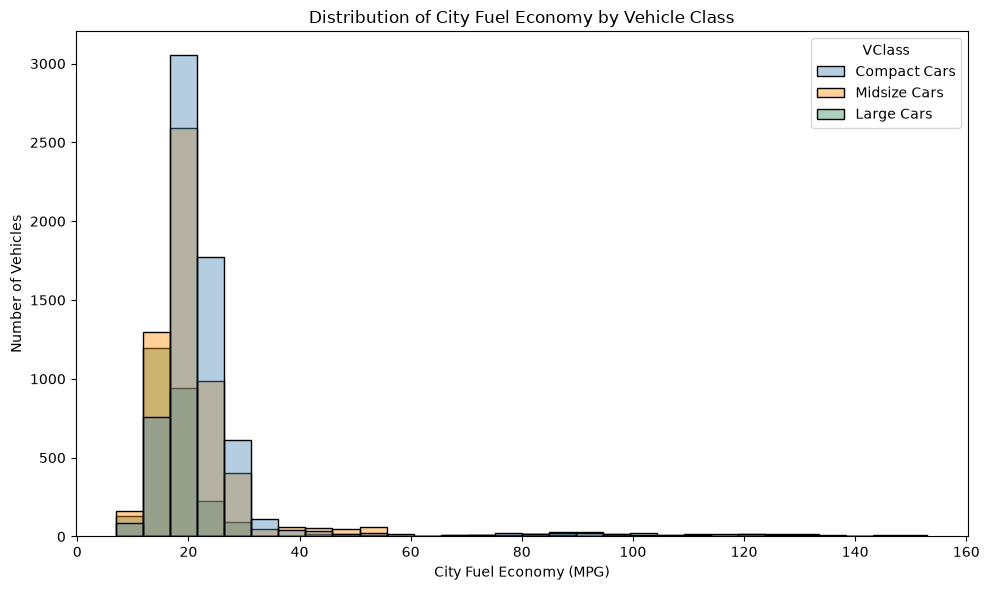

In [15]:
group_order = ["Compact Cars", "Midsize Cars", "Large Cars"]

group_colors = {
    "Compact Cars": "steelblue",
    "Midsize Cars": "darkorange",
    "Large Cars": "seagreen"
}

plt.figure(figsize=(10, 6))

sns.histplot(
    data=city_mpg_df,
    x="city08",
    hue="VClass",
    hue_order=group_order,
    palette=group_colors,
    bins=30,
    multiple="layer",
    alpha=0.4
)

plt.title("Distribution of City Fuel Economy by Vehicle Class")
plt.xlabel("City Fuel Economy (MPG)")
plt.ylabel("Number of Vehicles")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:


All three vehicle classes have most of their city fuel economy values concentrated between approximately 15 and 30 MPG, with substantial overlap among the groups. Compact Cars appear to have typical values around 20–25 MPG, while Midsize Cars and Large Cars are concentrated slightly lower, around 15–25 MPG. All three distributions are strongly right-skewed because most observations are clustered at lower MPG values while a much smaller number extend far to the right. There are unusual high-MPG observations above approximately 70 MPG, with some values reaching around 150 MPG.

The groups have unequal sample sizes. Compact Cars have 6,649 observations, Midsize Cars have 5,896, and Large Cars have 2,832. Because the histogram displays counts, the larger groups can produce taller bars simply because they contain more observations. Therefore, bar height alone should not be interpreted as evidence that one group has a greater proportion of vehicles within an MPG range.

In [16]:
city_summary = (
    city_mpg_df
    .groupby("VClass")["city08"]
    .describe()
    .reindex(group_order)
)

city_summary["IQR"] = city_summary["75%"] - city_summary["25%"]

city_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
VClass,,,,,,,,,
Compact Cars,6649.0,22.84,11.95,7.0,18.0,21.0,24.0,127.0,6.0
Midsize Cars,5896.0,23.01,17.27,7.0,17.0,18.0,23.0,153.0,6.0
Large Cars,2832.0,23.85,23.26,7.0,15.0,17.0,19.0,149.0,4.0


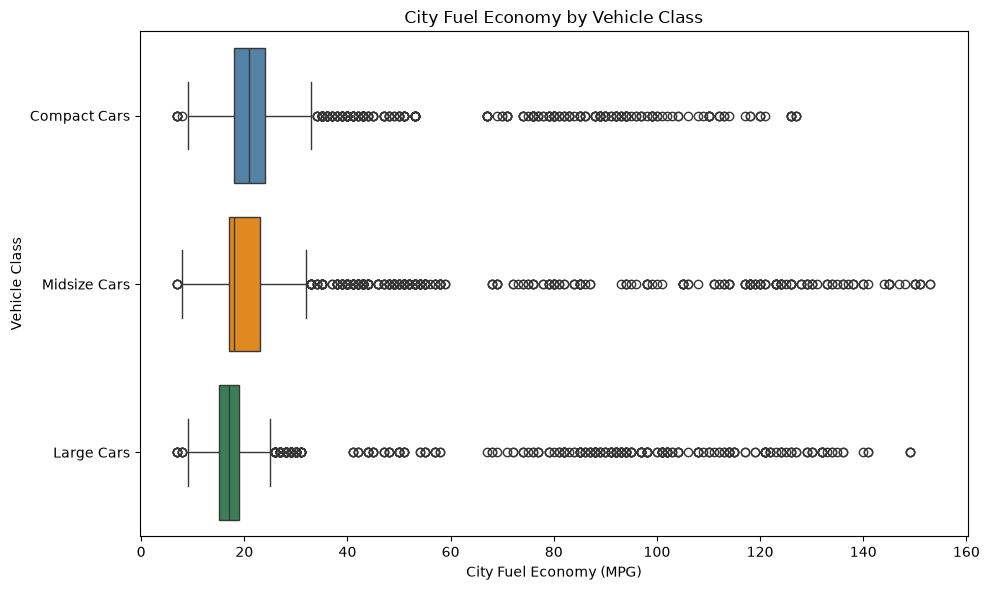

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=city_mpg_df,
    x="city08",
    y="VClass",
    order=group_order,
    hue="VClass",
    hue_order=group_order,
    palette=group_colors,
    legend=False
)

plt.title("City Fuel Economy by Vehicle Class")
plt.xlabel("City Fuel Economy (MPG)")
plt.ylabel("Vehicle Class")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:


The calculated summaries support my visual estimates. Compact Cars have the highest median city fuel economy at 21 MPG, compared with 18 MPG for Midsize Cars and 17 MPG for Large Cars. Compact and Midsize Cars have the same IQR of 6 MPG, while Large Cars have a smaller IQR of 4 MPG. The groups overlap substantially in their typical MPG ranges, but Compact Cars generally have a higher center. All three distributions are strongly right-skewed and contain high-MPG outliers. The histogram makes the overall shape, overlap, and relative frequencies easier to see, but the unequal group sizes affect the bar heights. The box plot makes the medians, IQRs, and unusual values easier to compare, but it does not show the groups' sample sizes or the detailed shape of each distribution.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [18]:
# Check the highest city MPG observations against the original records.
fuel_economy_df.loc[
    fuel_economy_df["VClass"].isin(
        ["Compact Cars", "Midsize Cars", "Large Cars"]
    )
].nlargest(10, "city08")[
    ["make", "model", "year", "VClass", "fuelType1", "city08"]
]

,make,model,year,VClass,fuelType1,city08
40254,Hyundai,Ioniq 6 Long range RWD (18 inch Wheels),2023,Midsize Cars,Electricity,153
40623,Hyundai,Ioniq 6 Long range RWD (18 inch Wheels),2024,Midsize Cars,Electricity,153
40256,Hyundai,Ioniq 6 Standard Range RWD,2023,Midsize Cars,Electricity,151
40625,Hyundai,Ioniq 6 Standard Range RWD,2024,Midsize Cars,Electricity,151
42181,Hyundai,Ioniq 6 Standard Range,2025,Midsize Cars,Electricity,151
31226,Hyundai,Ioniq Electric,2017,Midsize Cars,Electricity,150
32569,Hyundai,Ioniq Electric,2018,Midsize Cars,Electricity,150
33393,Hyundai,Ioniq Electric,2019,Midsize Cars,Electricity,150
37173,Tesla,Model 3 Standard Range Plus RWD,2021,Midsize Cars,Electricity,150
42192,Lucid,Air Pure RWD with 19 inch wheels,2025,Large Cars,Electricity,149


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:


I would be suspicious of the unusually high city fuel economy values because they are much higher than the typical values for all three vehicle classes. I checked the original records for the ten highest city MPG values and found that they range from 149 to 153 MPG and are all electric vehicles, including Hyundai Ioniq models, a Tesla Model 3, and a Lucid Air. This establishes that the extreme values correspond to actual electric-vehicle records rather than obvious data-entry errors. The maximum values also agree with the numerical summaries and plotted range. Therefore, I did not remove or correct these observations and retained them as valid extreme values in the analysis.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:


City fuel economy differs somewhat among the three vehicle classes, although the distributions overlap substantially. The analysis included 6,649 Compact Cars, 5,896 Midsize Cars, and 2,832 Large Cars. Compact Cars had the highest median at 21 MPG, followed by Midsize Cars at 18 MPG and Large Cars at 17 MPG. The IQR was 6 MPG for both Compact and Midsize Cars and 4 MPG for Large Cars. All three groups were strongly right-skewed because of high-MPG vehicles, particularly electric vehicles. Overall, the results support my prediction that Compact Cars would generally have higher city fuel economy than larger vehicles, although there was considerable overlap among the groups.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:


A reader should not conclude that vehicle class alone causes differences in city fuel economy. The dataset includes vehicles from different model years and with different fuel types and technologies, including electric vehicles, which can strongly affect fuel economy. This analysis describes the distributions for the vehicles represented in the dataset but does not control for these other factors.

## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer:


How does the distribution of highway fuel economy (MPG) differ among Compact Cars, Midsize Cars, and Large Cars in the FuelEconomy.gov vehicle dataset? The quantitative feature is highway08, measured in miles per gallon (MPG), and the categorical feature is VClass.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:


I predict that Compact Cars will generally have a higher center for highway fuel economy than Midsize and Large Cars. I expect substantial overlap among the three groups because vehicles within each class use different fuel types and technologies. I also expect the distributions to be right-skewed because electric and other highly efficient vehicles may have unusually high highway MPG values.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:


I will use the VClass and highway08 features and include only Compact Cars, Midsize Cars, and Large Cars. highway08 measures highway fuel economy in miles per gallon (MPG). The original DataFrame will remain unchanged because I will create a separate analysis DataFrame containing only the selected groups and features. highway08 has no missing values, so no observations need to be excluded for missing highway MPG. Each analyzed observation represents one vehicle record in the dataset.

In [19]:
highway_mpg_df = fuel_economy_df.loc[
    fuel_economy_df["VClass"].isin(
        ["Compact Cars", "Midsize Cars", "Large Cars"]
    ),
    ["VClass", "highway08"]
].copy()

highway_mpg_df.head()

,VClass,highway08
4,Compact Cars,23
5,Compact Cars,24
6,Compact Cars,29
7,Compact Cars,26
8,Compact Cars,31


In [20]:
highway_mpg_df["VClass"].value_counts()

VClass
Compact Cars    6649
Midsize Cars    5896
Large Cars      2832
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


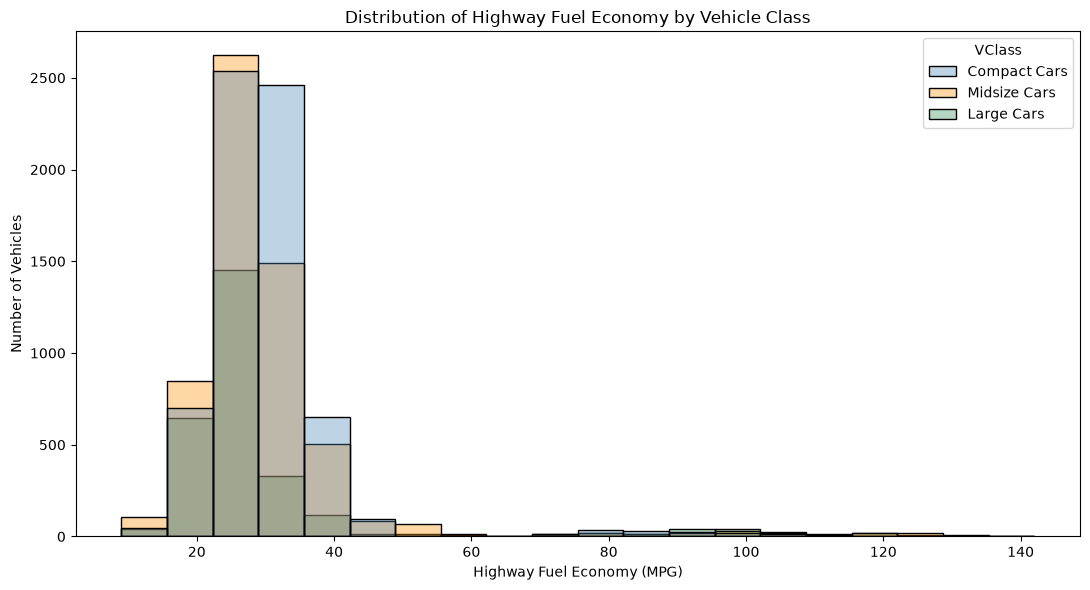

In [21]:
group_order = ["Compact Cars", "Midsize Cars", "Large Cars"]

plt.figure(figsize=(11, 6))

sns.histplot(
    data=highway_mpg_df,
    x="highway08",
    hue="VClass",
    hue_order=group_order,
    palette=["steelblue", "darkorange", "seagreen"],
    bins=20,
    fill=True,
    alpha=0.35
)

plt.title("Distribution of Highway Fuel Economy by Vehicle Class")
plt.xlabel("Highway Fuel Economy (MPG)")
plt.ylabel("Number of Vehicles")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:


The three groups overlap substantially, with most highway fuel economy values concentrated around 20–40 MPG. Compact Cars appear to have slightly higher typical values than Midsize and Large Cars, while Large Cars tend to be concentrated toward the lower end of this range. All three distributions are right-skewed, with a small number of unusually high values extending above 100 MPG and some approaching 140 MPG. The group sizes affect the histogram heights because Compact Cars have 6,649 observations, Midsize Cars have 5,896, and Large Cars have 2,832, so taller bars do not necessarily mean a larger proportion of that group falls in a particular range.

In [22]:
highway_summary = (
    highway_mpg_df
    .groupby("VClass")["highway08"]
    .describe()
    .reindex(group_order)
)

highway_summary["IQR"] = highway_summary["75%"] - highway_summary["25%"]

highway_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
VClass,,,,,,,,,
Compact Cars,6649.0,30.13,10.71,9.0,25.0,29.0,32.0,124.0,7.0
Midsize Cars,5896.0,29.83,13.93,9.0,24.0,27.0,32.0,133.0,8.0
Large Cars,2832.0,30.83,20.86,9.0,23.0,25.0,28.0,142.0,5.0


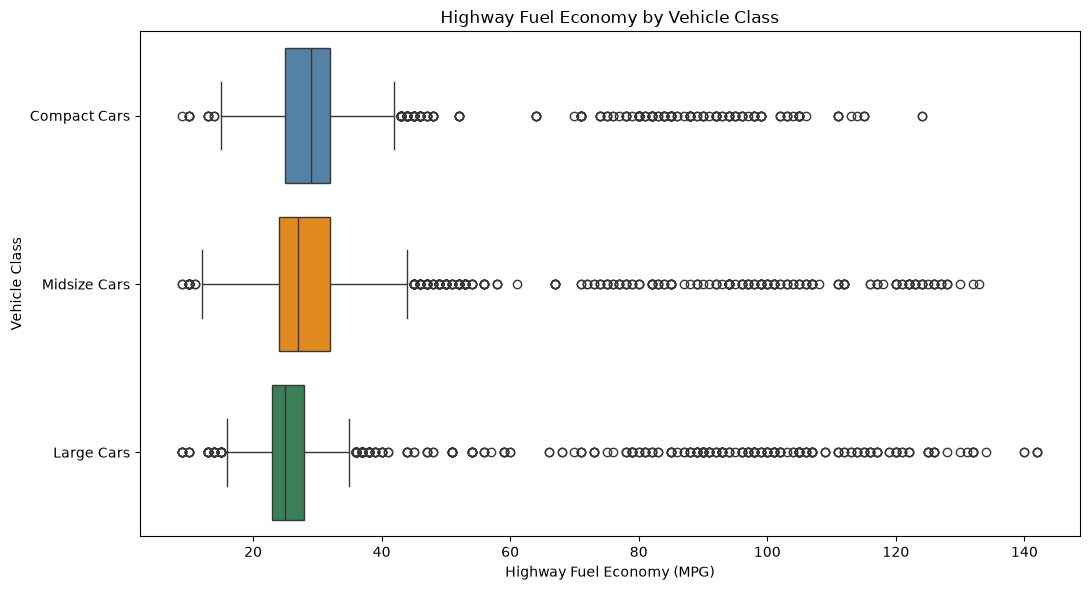

In [23]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=highway_mpg_df,
    x="highway08",
    y="VClass",
    order=group_order,
    hue="VClass",
    hue_order=group_order,
    palette=["steelblue", "darkorange", "seagreen"],
    legend=False
)

plt.title("Highway Fuel Economy by Vehicle Class")
plt.xlabel("Highway Fuel Economy (MPG)")
plt.ylabel("Vehicle Class")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:


The calculated summaries support my visual estimates. Compact Cars have the highest median highway fuel economy at 29 MPG, followed by Midsize Cars at 27 MPG and Large Cars at 25 MPG. The middle 50% of the observations also overlap substantially, with IQRs of 7 MPG for Compact Cars, 8 MPG for Midsize Cars, and 5 MPG for Large Cars. All three distributions are strongly right-skewed and contain high-MPG outliers, which explains why their means are all near 30 MPG even though their medians differ. Compact and Midsize Cars look the most similar, while Large Cars have a lower typical highway MPG. The histogram shows the distribution shape, overlap, and relative group sizes more clearly, while the box plot makes the medians, IQRs, and extreme values easier to compare but hides the detailed shape and group sizes.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [24]:
# Check the highest highway MPG observations against the original records.
fuel_economy_df.loc[
    fuel_economy_df["VClass"].isin(
        ["Compact Cars", "Midsize Cars", "Large Cars"]
    )
].nlargest(10, "highway08")[
    ["make", "model", "year", "VClass", "fuelType1", "highway08"]
]

,make,model,year,VClass,fuelType1,highway08
42192,Lucid,Air Pure RWD with 19 inch wheels,2025,Large Cars,Electricity,142
43947,Lucid,Air Pure RWD with 19 inch wheels,2026,Large Cars,Electricity,142
44920,Lucid,Air Pure RWD with 19 inch wheels,2027,Large Cars,Electricity,142
39906,Lucid,Air Pure AWD with 19 inch wheels,2023,Large Cars,Electricity,140
39908,Lucid,Air Touring AWD with 19 inch wheels,2023,Large Cars,Electricity,140
41174,Lucid,Air Pure RWD with 19 inch wheels,2024,Large Cars,Electricity,134
37173,Tesla,Model 3 Standard Range Plus RWD,2021,Midsize Cars,Electricity,133
35477,Tesla,Model 3 Standard Range Plus,2020,Midsize Cars,Electricity,132
37900,Lucid,Air G Touring AWD w/19 inch wheels,2022,Large Cars,Electricity,132
39902,Lucid,Air G Touring XR AWD with 19 inch wheels,2023,Large Cars,Electricity,132


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:


The unusually high highway MPG values made me suspicious because they were far above the typical values for all three vehicle classes. I checked the original records and found that the highest values belong to electric vehicles, including Lucid Air and Tesla Model 3 models. The maximum value of 142 MPG belongs to Lucid Air models classified as Large Cars. This establishes that the extreme values correspond to identifiable electric vehicles rather than obvious data-entry errors. I therefore kept these observations in the analysis and made no corrections. One limitation is that comparing electric and gasoline vehicles together can create extreme values and strongly right-skewed distributions because their fuel-economy measurements differ substantially.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:


Highway fuel economy differed somewhat among the three vehicle classes, although the distributions overlapped substantially. The analysis included 6,649 Compact Cars, 5,896 Midsize Cars, and 2,832 Large Cars. Compact Cars had the highest median at 29 MPG, followed by Midsize Cars at 27 MPG and Large Cars at 25 MPG. Their IQRs were 7 MPG, 8 MPG, and 5 MPG, respectively. All three distributions were strongly right-skewed because of high-MPG vehicles, including electric vehicles. Overall, the results support my prediction that smaller vehicles would generally have higher typical highway fuel economy, although there was considerable overlap among the groups.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:


A reader should not conclude that vehicle class alone causes differences in highway fuel economy. The dataset includes vehicles with different fuel types, model years, manufacturers, and technologies, including electric vehicles with unusually high MPG values. These factors can affect the distributions independently of vehicle class. The results describe the vehicles represented in this dataset and show an association between vehicle class and highway fuel economy, not a causal relationship.

## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer:


How does the distribution of combined fuel economy, measured in miles per gallon (MPG), differ among Compact Cars, Midsize Cars, and Large Cars in the fuel economy dataset?

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:


I predict that Compact Cars will have the highest typical combined fuel economy, followed by Midsize Cars and then Large Cars. I expect substantial overlap among the three groups because vehicles within each class vary in fuel type, model year, and technology. I also expect the distributions to be right-skewed because some highly efficient vehicles, particularly electric vehicles, may have much higher combined MPG values than most vehicles.

I predict that Compact Cars will have the highest typical combined fuel economy, followed by Midsize Cars and then Large Cars. I expect substantial overlap among the three groups because vehicles within each class vary in fuel type, model year, and technology. I also expect the distributions to be right-skewed because some highly efficient vehicles, particularly electric vehicles, may have much higher combined MPG values than most vehicles.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:


I will use records classified as Compact Cars, Midsize Cars, or Large Cars and compare the comb08 feature, which measures combined fuel economy in miles per gallon (MPG). One observation represents one vehicle record in the dataset. comb08 and VClass have no missing values, so no records need to be excluded for missing data. The original DataFrame will remain unchanged, and a separate DataFrame will contain only the selected vehicle classes and features.

In [25]:
combined_mpg_df = fuel_economy_df.loc[
    fuel_economy_df["VClass"].isin(
        ["Compact Cars", "Midsize Cars", "Large Cars"]
    ),
    ["VClass", "comb08"]
].copy()

combined_mpg_df.head()

,VClass,comb08
4,Compact Cars,19
5,Compact Cars,22
6,Compact Cars,25
7,Compact Cars,24
8,Compact Cars,26


In [26]:
combined_mpg_df["VClass"].value_counts()

VClass
Compact Cars    6649
Midsize Cars    5896
Large Cars      2832
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


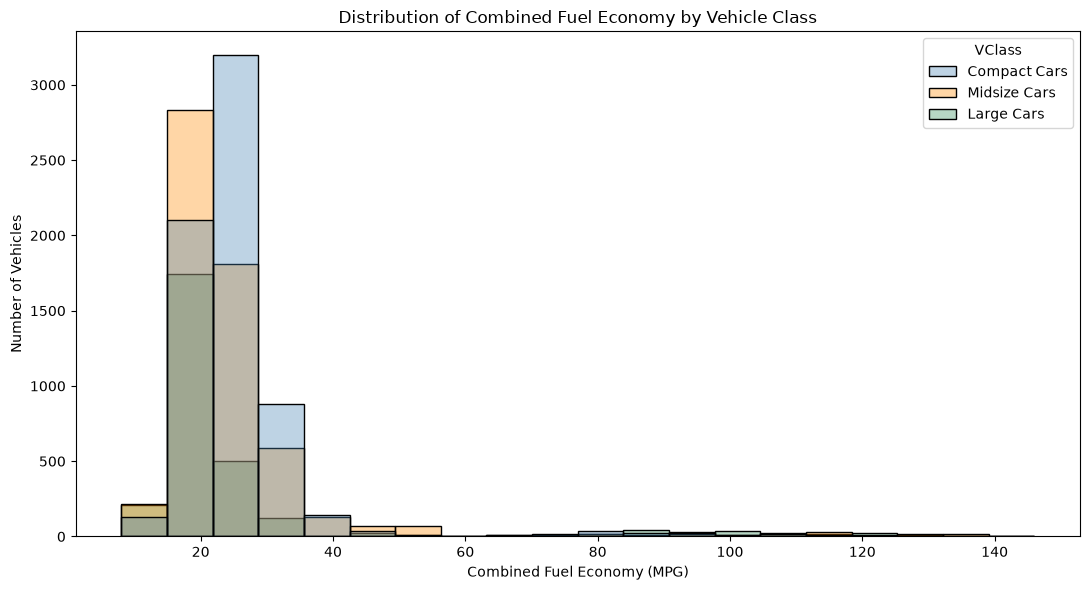

In [27]:
group_order = ["Compact Cars", "Midsize Cars", "Large Cars"]
group_colors = ["steelblue", "darkorange", "seagreen"]

plt.figure(figsize=(11, 6))

sns.histplot(
    data=combined_mpg_df,
    x="comb08",
    hue="VClass",
    hue_order=group_order,
    palette=group_colors,
    bins=20,
    fill=True,
    alpha=0.35
)

plt.title("Distribution of Combined Fuel Economy by Vehicle Class")
plt.xlabel("Combined Fuel Economy (MPG)")
plt.ylabel("Number of Vehicles")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:


The three groups overlap substantially, with most combined fuel economy values concentrated between about 15 and 35 MPG. Compact Cars appear to have the highest typical values, followed by Midsize Cars and then Large Cars. All three distributions are strongly right-skewed, with a small number of unusually high values extending above 100 MPG and approaching 150 MPG. Compact and Midsize Cars show especially strong overlap, while Large Cars appear somewhat more concentrated at lower MPG values. The groups are different sizes, with 6,649 Compact Cars, 5,896 Midsize Cars, and 2,832 Large Cars, so the histogram's count-based bar heights are affected by both the distribution and the number of vehicles in each group.

In [28]:
combined_summary = (
    combined_mpg_df
    .groupby("VClass")["comb08"]
    .describe()
    .reindex(group_order)
)

combined_summary["IQR"] = (
    combined_summary["75%"] - combined_summary["25%"]
)

combined_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
VClass,,,,,,,,,
Compact Cars,6649.0,25.52,11.40,8.0,20.0,24.0,27.0,126.0,7.0
Midsize Cars,5896.0,25.42,15.75,8.0,19.0,21.0,26.0,142.0,7.0
Large Cars,2832.0,26.34,22.28,8.0,18.0,20.0,23.0,146.0,5.0


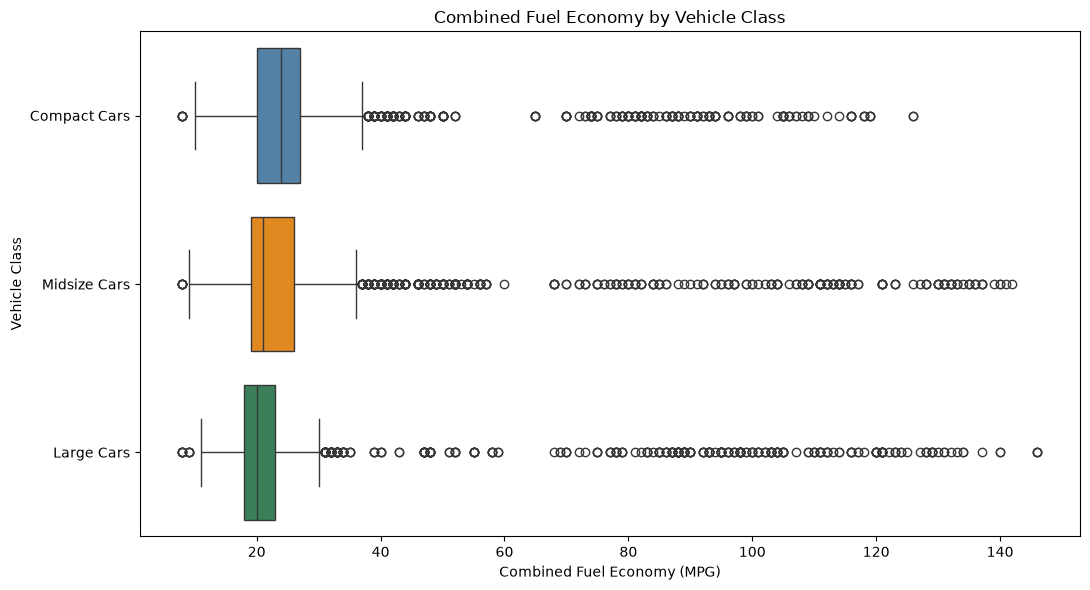

In [29]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=combined_mpg_df,
    x="comb08",
    y="VClass",
    order=group_order,
    hue="VClass",
    hue_order=group_order,
    palette=group_colors,
    legend=False
)

plt.title("Combined Fuel Economy by Vehicle Class")
plt.xlabel("Combined Fuel Economy (MPG)")
plt.ylabel("Vehicle Class")
plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:


The calculated summaries support my visual estimates. Compact Cars have the highest median combined fuel economy at 24 MPG, compared with 21 MPG for Midsize Cars and 20 MPG for Large Cars. Compact and Midsize Cars both have an IQR of 7 MPG, while Large Cars have a slightly smaller IQR of 5 MPG. The groups overlap substantially in their typical values, but Compact Cars are centered somewhat higher. All three distributions have high-MPG outliers and are strongly right-skewed. This is especially noticeable because the means (25.52 MPG, 25.42 MPG, and 26.34 MPG) are higher than the medians; Large Cars even have the highest mean despite having the lowest median. The histogram makes the distribution shape, overlap, and relative group sizes easier to see, while the box plot clearly shows the medians, IQRs, and extreme observations but hides the detailed shape and group sizes.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [30]:
# Check the highest combined MPG observations against the original records.
fuel_economy_df.loc[
    fuel_economy_df["VClass"].isin(
        ["Compact Cars", "Midsize Cars", "Large Cars"]
    )
].nlargest(10, "comb08")[
    ["make", "model", "year", "VClass", "fuelType1", "comb08"]
]

,make,model,year,VClass,fuelType1,comb08
42192,Lucid,Air Pure RWD with 19 inch wheels,2025,Large Cars,Electricity,146
43947,Lucid,Air Pure RWD with 19 inch wheels,2026,Large Cars,Electricity,146
44920,Lucid,Air Pure RWD with 19 inch wheels,2027,Large Cars,Electricity,146
37173,Tesla,Model 3 Standard Range Plus RWD,2021,Midsize Cars,Electricity,142
35477,Tesla,Model 3 Standard Range Plus,2020,Midsize Cars,Electricity,141
39906,Lucid,Air Pure AWD with 19 inch wheels,2023,Large Cars,Electricity,140
39908,Lucid,Air Touring AWD with 19 inch wheels,2023,Large Cars,Electricity,140
40254,Hyundai,Ioniq 6 Long range RWD (18 inch Wheels),2023,Midsize Cars,Electricity,140
40623,Hyundai,Ioniq 6 Long range RWD (18 inch Wheels),2024,Midsize Cars,Electricity,140
44261,Tesla,Model 3 Standard RWD,2026,Midsize Cars,Electricity,139


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:


The very high combined MPG values made me suspicious because they are far above the typical values for all three vehicle classes. I checked the original records for the highest values and found that they belong to electric vehicles, including Lucid, Tesla, and Hyundai models. For example, the highest value was 146 MPG for the Lucid Air Pure. This supports treating the extreme values as valid observations rather than errors, so I did not remove them. No correction was necessary, although the presence of electric vehicles helps explain the strong right-skew and high-value outliers in the distribution.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:


Combined fuel economy differed somewhat among the three vehicle classes, although the distributions had substantial overlap. Compact Cars had the highest median at 24 MPG (n = 6,649), followed by Midsize Cars at 21 MPG (n = 5,896) and Large Cars at 20 MPG (n = 2,832). The IQR was 7 MPG for both Compact and Midsize Cars and 5 MPG for Large Cars. All three distributions were strongly right-skewed because of high-MPG vehicles, with maximum values of 126 MPG for Compact Cars, 142 MPG for Midsize Cars, and 146 MPG for Large Cars. This generally supports my prediction that compact cars would have a higher typical combined fuel economy, although there was more overlap between the vehicle classes than I expected.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:


A reader should not conclude that vehicle class alone causes differences in combined fuel economy. The dataset includes vehicles with different fuel types, including electric vehicles, which account for many of the extremely high MPG values. Other factors such as model year, engine type, and vehicle technology may also affect fuel economy. Therefore, these results describe the vehicles in this dataset but do not establish that vehicle class itself causes the observed differences

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:


Yes. I used ChatGPT to help me check how to investigate the unusually high MPG values in my results. It suggested comparing the extreme values with the original vehicle records. I checked the output and confirmed that the highest values belonged to electric vehicles, so I accepted the suggestion and kept those observations in the analysis rather than treating them as errors.

## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
